# Лабораторная работа №2: Классификация (Titanic)

**Цель:** пройти полный цикл решения задачи бинарной классификации — анализ данных, baseline, сравнение пяти алгоритмов, анализ метрик, ошибок и важности признаков.

**Целевая переменная:** `Survived` (1 — выжил, 0 — нет).
**Основная метрика:** F1-score для класса `Survived = 1`. **Порог:** F1 > 0.70.

Датасет: [Titanic Dataset (Kaggle, yasserh)](https://www.kaggle.com/datasets/yasserh/titanic-dataset), файл `data/Titanic-Dataset.csv` (891 пассажир).

**Схема эксперимента (защита от утечек):**
1. Разбиение train/test (80/20, стратификация по `Survived`, `random_state=42`) делается **до** любых преобразований, параметры которых оцениваются по данным.
2. Импутация, кодирование, масштабирование — внутри `sklearn.Pipeline`, поэтому их параметры обучаются только на train (и внутри кросс-валидации — только на обучающих фолдах).
3. Гиперпараметры подбираются кросс-валидацией **на train**, лучшая модель выбирается тоже по CV. Тестовая выборка используется только для финальной оценки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
F1_THRESHOLD = 0.70

## 1. Первичный анализ данных

In [2]:
df = pd.read_csv("data/Titanic-Dataset.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
})
summary

,dtype,n_unique,n_missing,missing_%
PassengerId,int64,891,0,0.0
Survived,int64,2,0,0.0
Pclass,int64,3,0,0.0
Name,str,891,0,0.0
Sex,str,2,0,0.0
Age,float64,88,177,19.9
SibSp,int64,7,0,0.0
Parch,int64,7,0,0.0
Ticket,str,681,0,0.0
Fare,float64,248,0,0.0


In [5]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
df.describe()

Полных дубликатов строк: 0
Дубликатов без PassengerId: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Распределение целевой переменной

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


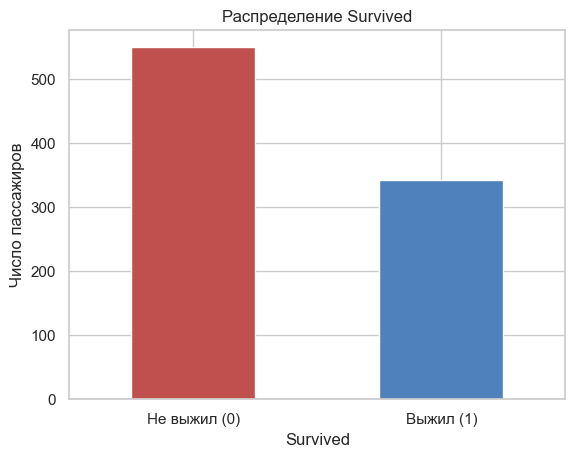

In [6]:
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(3))

ax = df["Survived"].value_counts().sort_index().plot.bar(color=["#c0504d", "#4f81bd"], rot=0)
ax.set_xticklabels(["Не выжил (0)", "Выжил (1)"])
ax.set_title("Распределение Survived"); ax.set_ylabel("Число пассажиров")
plt.show()

### Связь признаков с выживаемостью

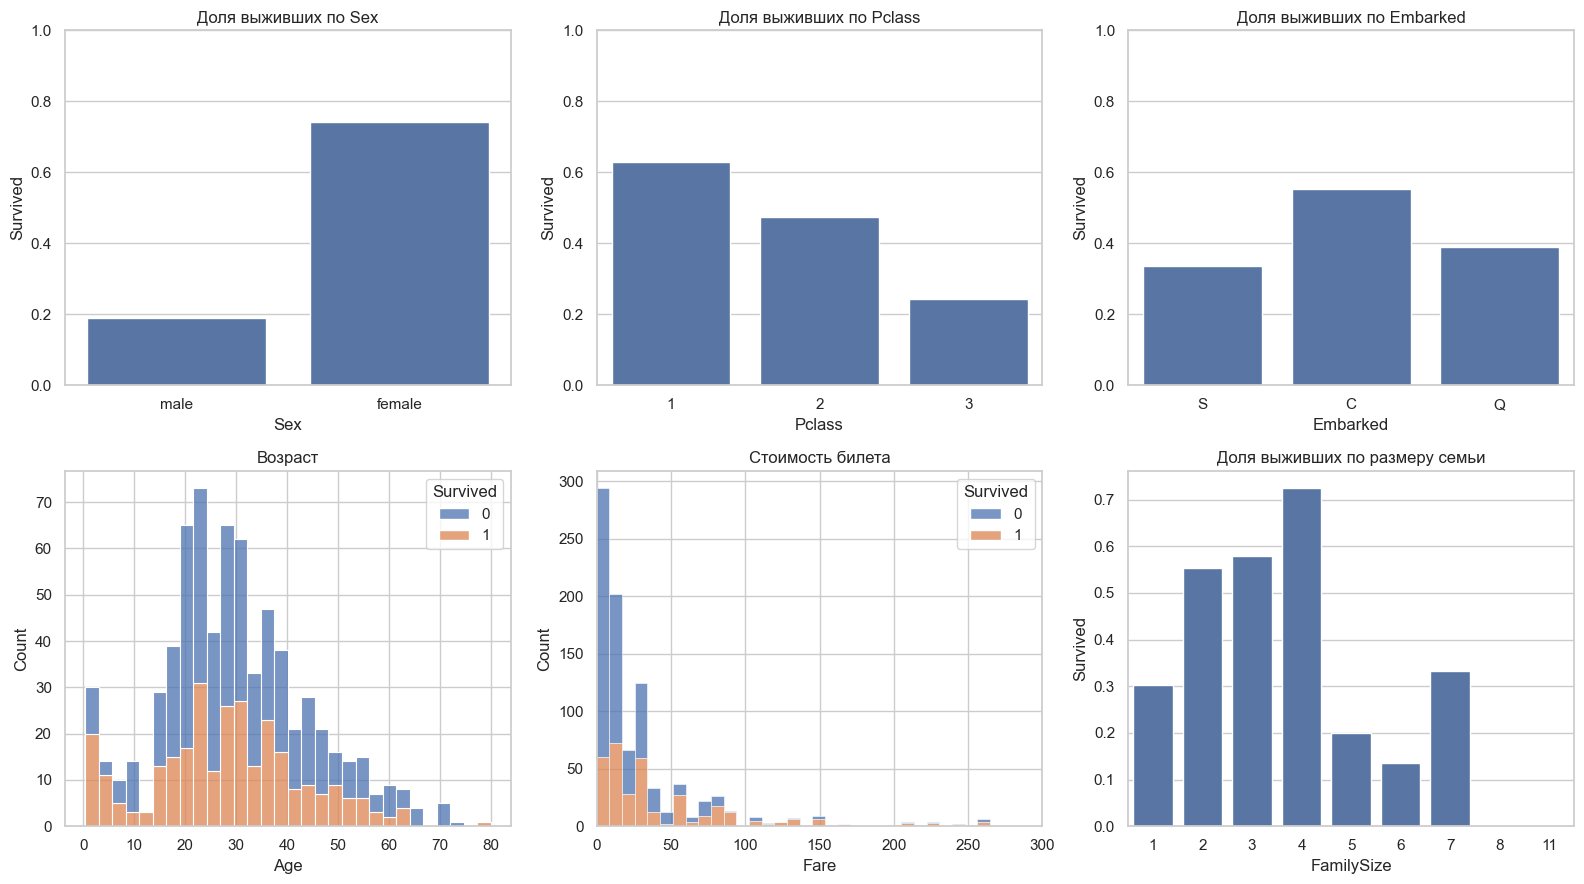

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes[0], ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df, x=col, y="Survived", ax=ax, errorbar=None)
    ax.set_title(f"Доля выживших по {col}"); ax.set_ylim(0, 1)

sns.histplot(data=df, x="Age", hue="Survived", bins=30, ax=axes[1, 0], multiple="stack")
axes[1, 0].set_title("Возраст")
sns.histplot(data=df, x="Fare", hue="Survived", bins=60, ax=axes[1, 1], multiple="stack")
axes[1, 1].set_title("Стоимость билета"); axes[1, 1].set_xlim(0, 300)
family_size = df["SibSp"] + df["Parch"] + 1
sns.barplot(x=family_size, y=df["Survived"], ax=axes[1, 2], errorbar=None)
axes[1, 2].set_title("Доля выживших по размеру семьи"); axes[1, 2].set_xlabel("FamilySize")
plt.tight_layout(); plt.show()

In [8]:
print("Доля выживших: класс x пол")
print(pd.crosstab(df["Pclass"], df["Sex"], values=df["Survived"], aggfunc="mean").round(2))
print("\nДоля выживших: каюта известна?")
print(df.groupby(df["Cabin"].notna())["Survived"].mean().round(3))
print("\nДоля выживших: возраст пропущен?")
print(df.groupby(df["Age"].isna())["Survived"].mean().round(3))

Доля выживших: класс x пол
Sex     female  male
Pclass              
1         0.97  0.37
2         0.92  0.16
3         0.50  0.14

Доля выживших: каюта известна?
Cabin
False    0.300
True     0.667
Name: Survived, dtype: float64

Доля выживших: возраст пропущен?
Age
False    0.406
True     0.294
Name: Survived, dtype: float64


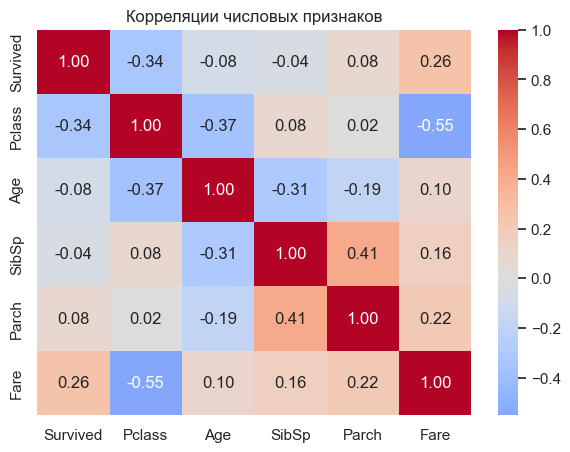

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков"); plt.show()

### Признаки-идентификаторы и признаки с риском утечки

In [10]:
for col in ["PassengerId", "Name", "Ticket", "Cabin"]:
    print(f"{col:12s}: уникальных {df[col].nunique():4d} из {df[col].notna().sum()} непустых")
df[["PassengerId", "Name", "Ticket", "Cabin"]].sample(5, random_state=RANDOM_STATE)

PassengerId : уникальных  891 из 891 непустых
Name        : уникальных  891 из 891 непустых
Ticket      : уникальных  681 из 891 непустых
Cabin       : уникальных  147 из 204 непустых


,PassengerId,Name,Ticket,Cabin
709,710,"Moubarek, Master. Halim Gonios (""William George"")",2661,NaN
439,440,"Kvillner, Mr. Johan Henrik Johannesson",C.A. 18723,NaN
840,841,"Alhomaki, Mr. Ilmari Rudolf",SOTON/O2 3101287,NaN
720,721,"Harper, Miss. Annie Jessie ""Nina""",248727,NaN
39,40,"Nicola-Yarred, Miss. Jamila",2651,NaN


### Выводы по первичному анализу

* **Объём и типы.** 891 объект, 11 признаков + целевая. Числовые: `Pclass` (по смыслу порядковый категориальный), `Age`, `SibSp`, `Parch`, `Fare`; категориальные: `Sex`, `Embarked`; текстовые/идентификаторы: `Name`, `Ticket`, `Cabin`, `PassengerId`.
* **Пропуски:** `Cabin` — 77% (687 из 891), `Age` — ~20% (177), `Embarked` — 2 строки. Дубликатов нет.
* **Целевая переменная** умеренно несбалансирована: 61.6% погибли, 38.4% выжили. Accuracy поэтому недостаточна: модель «все погибли» уже даёт ~62% accuracy при F1 = 0 — отсюда выбор F1 по классу 1 как основной метрики.
* **Сильнейшие сигналы:** пол (выжили ~74% женщин и ~19% мужчин), класс (1-й ~63%, 3-й ~24%) и их сочетание (женщины 1–2 класса — >90%, мужчины 2–3 класса — <16%). Также `Fare` (коррелирует с классом, r ≈ −0.55), возраст (дети выживали чаще), размер семьи (одиночки и большие семьи — хуже, семьи из 2–4 человек — лучше). Правило «женщины и дети — первыми» хорошо видно в данных.
* **Пропуски информативны:** при известной каюте выжили ~67%, при неизвестной ~30% — факт записи каюты связан с классом/статусом. Пропущенный возраст тоже связан с более низкой выживаемостью. Поэтому сохраняем индикаторы пропусков.
* **Признаки, требующие особой обработки / риск запоминания:**
  * `PassengerId` — номер строки, уникален → бессмысленное запоминание объектов, **удаляем**.
  * `Name` — уникально у каждого пассажира → как есть использовать нельзя (модель запомнит конкретных людей). Извлекаем только обобщающийся признак — **титул** (Mr/Mrs/Miss/Master/…), который кодирует пол, возраст и статус.
  * `Ticket` — 681 уникальное значение на 891 пассажира, почти идентификатор; общие билеты попутчиков могут «переносить» таргет между train и test → **удаляем**.
  * `Cabin` — 77% пропусков, значения почти уникальны → оставляем только бинарный признак `HasCabin`.

## 2. Подготовка данных и выборок

**Feature engineering** — построчные детерминированные преобразования (никаких параметров по данным не оцениваются, поэтому их можно применить до разбиения без утечки):
* `Title` — титул из `Name`; редкие титулы (Dr, Rev, Col, …) объединяем в `Rare`, синонимы `Mlle`, `Ms` → `Miss`, `Mme` → `Mrs`;
* `FamilySize = SibSp + Parch + 1`, `IsAlone = (FamilySize == 1)`;
* `HasCabin` — известна ли каюта.

Удаляем `PassengerId`, `Name`, `Ticket`, `Cabin`.

In [11]:
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
MAIN_TITLES = ["Mr", "Mrs", "Miss", "Master"]

def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    title = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip().replace(TITLE_MAP)
    d["Title"] = title.where(title.isin(MAIN_TITLES), "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    return d.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X = make_features(df.drop(columns="Survived"))
y = df["Survived"]
print(pd.crosstab(X["Title"], y, margins=True))
X.head()

Survived    0    1  All
Title                  
Master     17   23   40
Miss       55  130  185
Mr        436   81  517
Mrs        26  100  126
Rare       15    8   23
All       549  342  891


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


### Разбиение train / test

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("train:", X_train.shape, " test:", X_test.shape)
print("Доля Survived=1  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

train: (712, 11)  test: (179, 11)
Доля Survived=1  train: 0.383  test: 0.385


### Препроцессинг (обучается только на train)

| Признаки | Обработка | Обоснование |
|---|---|---|
| `Age`, `Fare` и прочие числовые | `SimpleImputer(median, add_indicator=True)` | медиана устойчива к выбросам (у `Fare` длинный хвост); индикатор пропуска (`missingindicator_Age`) сохраняет информацию «возраст неизвестен», связанную с выживанием |
| `Sex`, `Embarked`, `Title` | `SimpleImputer(most_frequent)` + `OneHotEncoder(handle_unknown="ignore")` | номинальные категории без порядка; у `Embarked` всего 2 пропуска — мода (`S`) не исказит распределение |
| `Pclass` | как числовой | признак порядковый (1 < 2 < 3), порядок осмысленный |
| Масштабирование | `StandardScaler` — **только для SVM и KNN** | см. ниже |

**Для каких алгоритмов важно масштабирование:**
* **Decision Tree, Random Forest, Gradient Boosting** — не нужно: разбиения вида `x_j < t` инвариантны к монотонным преобразованиям признака.
* **SVM (RBF-ядро)** — нужно: ядро `exp(-γ‖x−x'‖²)` и отступ зависят от расстояний. Без масштабирования `Fare` (0–512) доминирует над бинарными признаками (0/1), и `Sex` почти перестаёт влиять.
* **KNN** — критично: модель целиком определяется евклидовым расстоянием между объектами.

Все преобразования находятся внутри `Pipeline`, поэтому `fit` вызывается только на train (и только на обучающих фолдах при кросс-валидации).

In [13]:
NUM_FEATURES = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
CAT_FEATURES = ["Sex", "Embarked", "Title"]

def make_preprocessor(scale: bool, cat_features=CAT_FEATURES) -> ColumnTransformer:
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [("impute", SimpleImputer(strategy="most_frequent")),
                 ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    return ColumnTransformer(
        [("num", Pipeline(num_steps), NUM_FEATURES), ("cat", Pipeline(cat_steps), cat_features)],
        verbose_feature_names_out=False)

make_preprocessor(scale=False).fit(X_train).get_feature_names_out()

array(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone',
       'HasCabin', 'missingindicator_Age', 'Sex_female', 'Sex_male',
       'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master',
       'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'], dtype=object)

## 3. Метрики и вспомогательные функции

* **Accuracy** — доля верных ответов; при соотношении классов 62/38 обманчива.
* **Precision** (класс 1) — из тех, кого модель назвала выжившими, какая доля действительно выжила.
* **Recall** (класс 1) — какую долю реально выживших модель нашла.
* **F1** — гармоническое среднее Precision и Recall; низкое, если проседает любая из них.

**FP и FN в контексте задачи:**
* **False Positive** — модель сказала «выжил», а пассажир погиб. Если бы прогноз использовался для решения, кому нужна помощь, FP — это «ложная уверенность»: человек в реальной опасности отнесён к «в безопасности».
* **False Negative** — модель сказала «погиб», а пассажир выжил: модель «не нашла» выжившего (например, в сценарии поиска выживших это пропущенный человек).

Для F1 оба типа ошибок важны: FP снижает Precision, FN — Recall.

In [14]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}        # метрики на test
train_results = {}  # метрики на train (для анализа переобучения)
fitted = {}

def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

def evaluate(name, model):
    # модель уже обучена на train; test используется только для оценки
    fitted[name] = model
    train_results[name] = metrics(y_train, model.predict(X_train))
    y_pred = model.predict(X_test)
    results[name] = metrics(y_test, y_pred)
    display(pd.DataFrame({"train": train_results[name], "test": results[name]}).T.round(3))
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ConfusionMatrixDisplay(cm, display_labels=["Погиб (0)", "Выжил (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}: confusion matrix (test)")
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}  ->  ложных 'выжил': {fp}, пропущенных выживших: {fn}")

def tune(name, estimator, grid, scale):
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", estimator)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=CV, n_jobs=-1).fit(X_train, y_train)
    print(f"{name}: лучшие параметры {gs.best_params_}, CV F1 = {gs.best_score_:.3f}")
    return gs.best_estimator_

def importances(model):
    names = model.named_steps["prep"].get_feature_names_out()
    return pd.Series(model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)

def plot_importances(imp, title, top=15):
    imp.head(top)[::-1].plot.barh(figsize=(7, 5), color="#4f81bd")
    plt.title(title); plt.xlabel("importance"); plt.tight_layout(); plt.show()

## 4. Baseline: Dummy (самый частый класс)

,Accuracy,Precision,Recall,F1
train,0.617,0.0,0.0,0.0
test,0.615,0.0,0.0,0.0


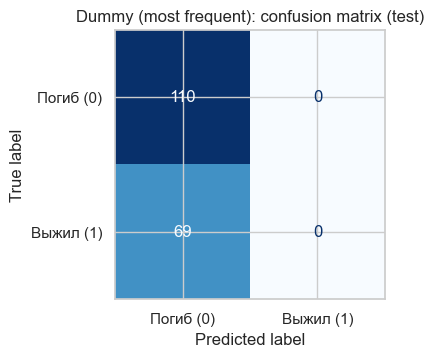

TN=110  FP=0  FN=69  TP=0  ->  ложных 'выжил': 0, пропущенных выживших: 69


In [15]:
dummy = Pipeline([("prep", make_preprocessor(False)),
                  ("model", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
evaluate("Dummy (most frequent)", dummy)

Baseline всегда предсказывает «погиб» (класс 0 — 61.6% в train). Accuracy ≈ 0.61, но Precision = Recall = F1 = 0: ни одного выжившего модель не находит, все 69 выживших в test — False Negative. Это наглядно показывает, почему Accuracy нельзя использовать как основную метрику, и задаёт нижнюю планку для остальных моделей.

## 5. Модели

Гиперпараметры каждой модели подбираются `GridSearchCV` (5-fold stratified CV, метрика F1) **только на train**. Сетки небольшие — цель не выжать максимум, а сравнить алгоритмы в одинаковых условиях.

### 5.1 Decision Tree

Сначала — дерево без ограничений, чтобы увидеть переобучение:

In [16]:
dt_full = Pipeline([("prep", make_preprocessor(False)),
                    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
print("Глубина:", dt_full.named_steps["model"].get_depth(), " листьев:", dt_full.named_steps["model"].get_n_leaves())
pd.DataFrame({"train": metrics(y_train, dt_full.predict(X_train)),
              "test": metrics(y_test, dt_full.predict(X_test))}).T.round(3)

Глубина: 22  листьев: 157


,Accuracy,Precision,Recall,F1
train,0.987,0.996,0.971,0.983
test,0.793,0.729,0.739,0.734


Теперь подбираем глубину и минимальный размер листа по CV:

Decision Tree: лучшие параметры {'model__max_depth': 3, 'model__min_samples_leaf': 1}, CV F1 = 0.762


,Accuracy,Precision,Recall,F1
train,0.831,0.812,0.729,0.768
test,0.832,0.820,0.725,0.769


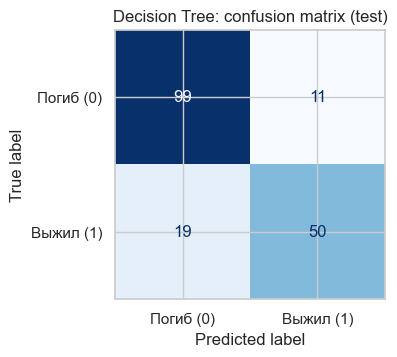

TN=99  FP=11  FN=19  TP=50  ->  ложных 'выжил': 11, пропущенных выживших: 19


In [17]:
dt = tune("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
          {"model__max_depth": [2, 3, 4, 5, 6, 8, None], "model__min_samples_leaf": [1, 5, 10, 20]}, scale=False)
evaluate("Decision Tree", dt)

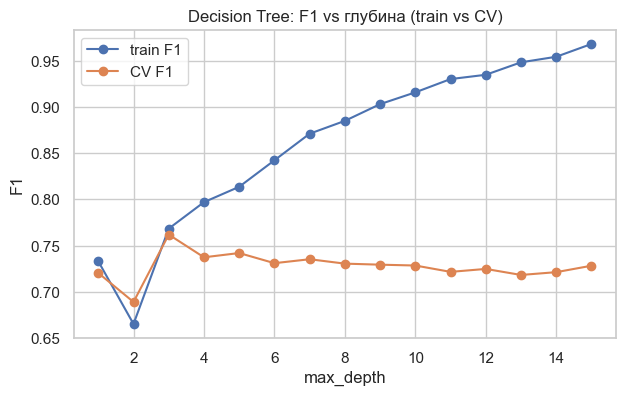

In [18]:
rows = []
for d in range(1, 16):
    m = Pipeline([("prep", make_preprocessor(False)),
                  ("model", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    cv_f1 = cross_val_score(m, X_train, y_train, cv=CV, scoring="f1").mean()
    m.fit(X_train, y_train)
    rows.append({"max_depth": d, "train F1": f1_score(y_train, m.predict(X_train)), "CV F1": cv_f1})
pd.DataFrame(rows).set_index("max_depth").plot(marker="o", figsize=(7, 4),
                                               title="Decision Tree: F1 vs глубина (train vs CV)")
plt.ylabel("F1"); plt.show()

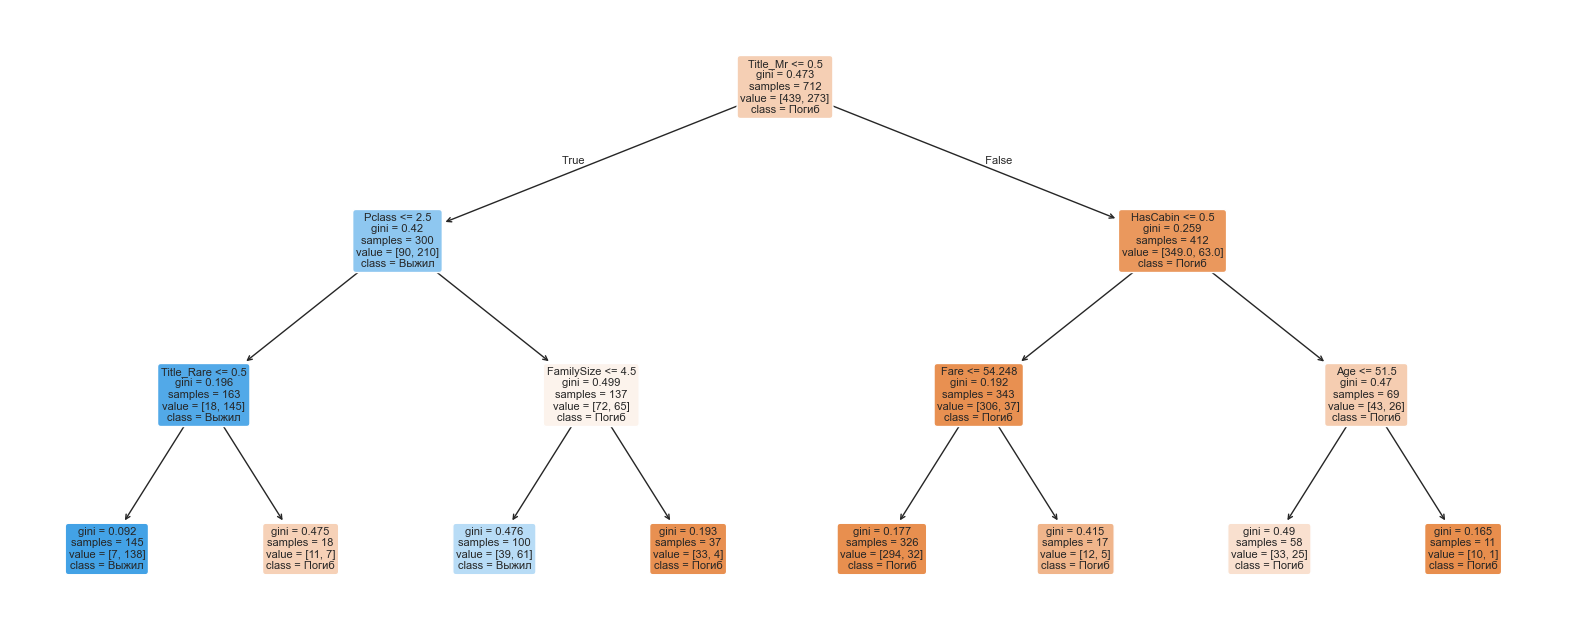

In [19]:
plt.figure(figsize=(20, 8))
plot_tree(dt.named_steps["model"], feature_names=dt.named_steps["prep"].get_feature_names_out(),
          class_names=["Погиб", "Выжил"], filled=True, rounded=True, fontsize=8)
plt.show()

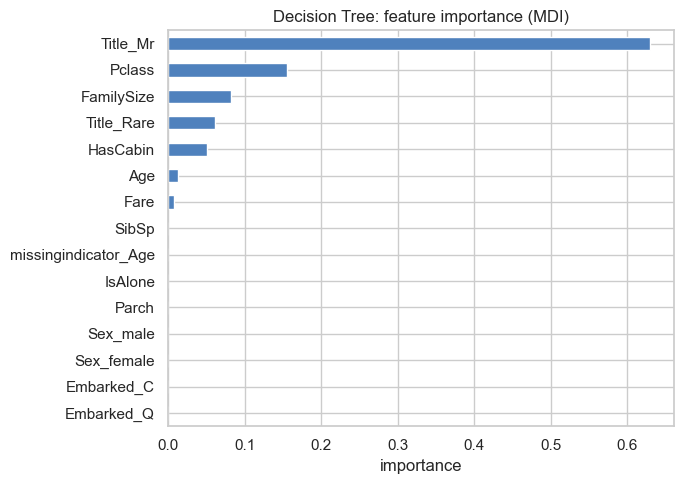

Title_Mr      0.630
Pclass        0.155
FamilySize    0.082
Title_Rare    0.061
HasCabin      0.050
Age           0.013
Fare          0.008
SibSp         0.000
dtype: float64

In [20]:
imp_dt = importances(dt)
plot_importances(imp_dt, "Decision Tree: feature importance (MDI)")
imp_dt.head(8).round(3)

**Выводы по Decision Tree.**
* **Переобучение есть у дерева без ограничений:** глубина 22, 157 листьев, train F1 = 0.983 против test F1 = 0.734 (Accuracy 0.987 → 0.793). Дерево фактически запомнило обучающую выборку, включая шум.
* **Подобранное по CV дерево (`max_depth=3`)** признаков переобучения не показывает: train F1 = 0.768, test F1 = 0.769, CV F1 = 0.762 — все три оценки совпадают. На кривой «F1 vs глубина» train-F1 монотонно растёт с глубиной, а CV-F1 после глубины 3–4 перестаёт расти и колеблется/падает — классическая картина роста дисперсии.
* **Ошибки (test):** FP = 11, FN = 19 — модель чаще пропускает выживших, чем ошибочно «спасает» погибших (Recall 0.725 < Precision 0.820).
* **Feature importance:** дерево почти всё решает одним признаком `Title_Mr` (0.63) — «взрослый мужчина или нет», затем `Pclass` (0.155) и `FamilySize` (0.08). `Sex` имеет нулевую важность не потому, что пол не важен, а потому что `Title_Mr` уже содержит информацию о поле (и дополнительно отделяет мальчиков `Master`); дерево выбирает один из коррелированных признаков, и вся важность достаётся ему.

### 5.2 Random Forest

Random Forest: лучшие параметры {'model__max_depth': 4, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}, CV F1 = 0.773


,Accuracy,Precision,Recall,F1
train,0.837,0.815,0.744,0.778
test,0.799,0.770,0.681,0.723


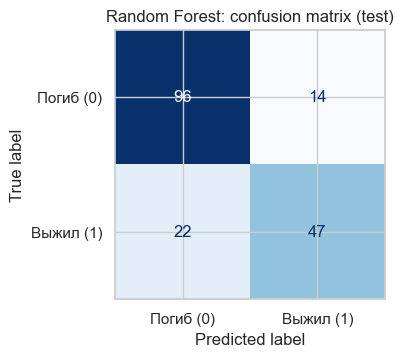

TN=96  FP=14  FN=22  TP=47  ->  ложных 'выжил': 14, пропущенных выживших: 22


In [21]:
rf = tune("Random Forest", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
          {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5],
           "model__max_features": ["sqrt", 0.5]}, scale=False)
evaluate("Random Forest", rf)

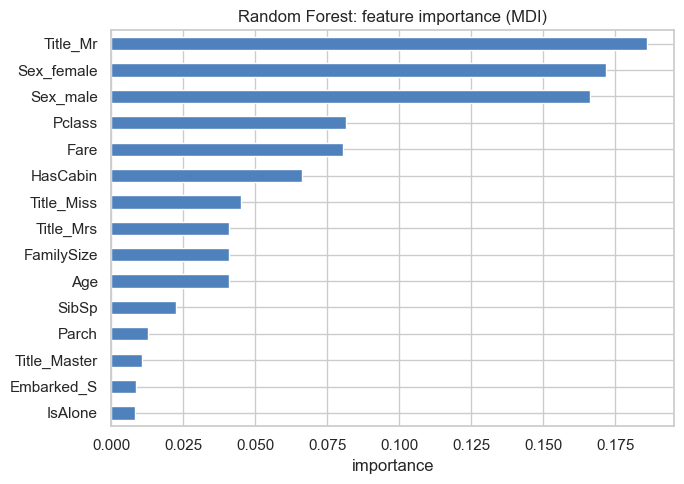

Title_Mr      0.186
Sex_female    0.172
Sex_male      0.166
Pclass        0.082
Fare          0.080
HasCabin      0.066
Title_Miss    0.045
Title_Mrs     0.041
dtype: float64

In [22]:
imp_rf = importances(rf)
plot_importances(imp_rf, "Random Forest: feature importance (MDI)")
imp_rf.head(8).round(3)

**Выводы по Random Forest.**
* Лучшие параметры по CV: 300 деревьев, `max_depth=4`, `max_features="sqrt"`. Train F1 = 0.778, test F1 = 0.723, CV F1 = 0.773 — сильного переобучения нет; разница train/test в пределах разброса CV (std ≈ 0.045).
* На test FP = 14, FN = 22 — так же, как и у дерева, преобладают пропущенные выжившие (Recall 0.681).
* **Сравнение важности с Decision Tree.** Набор главных признаков тот же — пол/титул и класс, — но распределение важности гораздо «ровнее»: `Title_Mr` 0.19, `Sex_female` 0.17, `Sex_male` 0.17, `Pclass` 0.08, `Fare` 0.08, `HasCabin` 0.07. Причина — `max_features="sqrt"`: в каждом разбиении доступна лишь часть признаков, поэтому деревья по очереди используют взаимозаменяемые `Title_Mr`/`Sex_*` и делят важность между ними. Заметнее становятся `Fare` и `Age` — непрерывные признаки, у которых много возможных порогов (MDI-важность их систематически завышает).

### 5.3 Gradient Boosting

Gradient Boosting: лучшие параметры {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}, CV F1 = 0.776


,Accuracy,Precision,Recall,F1
train,0.841,0.815,0.758,0.786
test,0.788,0.754,0.667,0.708


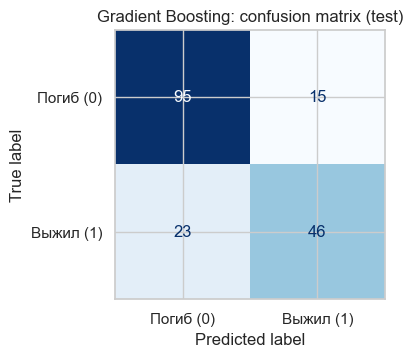

TN=95  FP=15  FN=23  TP=46  ->  ложных 'выжил': 15, пропущенных выживших: 23


In [23]:
gb = tune("Gradient Boosting", GradientBoostingClassifier(random_state=RANDOM_STATE),
          {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.1],
           "model__max_depth": [2, 3], "model__subsample": [0.8, 1.0]}, scale=False)
evaluate("Gradient Boosting", gb)

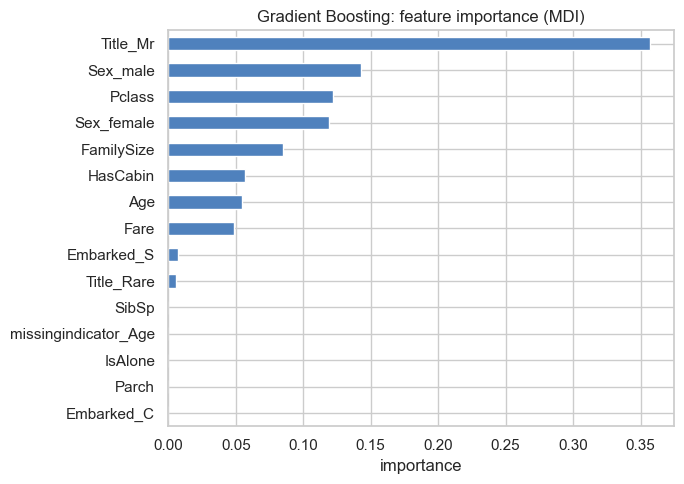

Title_Mr      0.357
Sex_male      0.143
Pclass        0.122
Sex_female    0.119
FamilySize    0.085
HasCabin      0.057
Age           0.055
Fare          0.049
dtype: float64

In [24]:
imp_gb = importances(gb)
plot_importances(imp_gb, "Gradient Boosting: feature importance (MDI)")
imp_gb.head(8).round(3)

**Выводы по Gradient Boosting.**
* По CV выбрана наиболее «осторожная» конфигурация: 100 деревьев глубины 2, `learning_rate=0.03`. Train F1 = 0.786, CV F1 = 0.776 (лучший CV в 5-fold), но на test F1 = 0.708 — минимальный среди моделей, хотя порог пройден.
* Разрыв train → test (0.786 → 0.708) больше, чем у RF, однако CV-оценка на train почти совпадает с train-F1, поэтому это скорее неудачная для бустинга тестовая выборка (69 выживших в test — изменение одного TP меняет F1 примерно на 0.01), чем явное переобучение.
* **Сравнение с Random Forest:** по качеству модели статистически неразличимы (CV F1 0.766 vs 0.771 при std ≈ 0.045, test 0.708 vs 0.723). Важность у бустинга более концентрированная: `Title_Mr` 0.36, далее `Sex_male`/`Sex_female` (суммарно 0.26), `Pclass` 0.12, `FamilySize` 0.085. Бустинг строит деревья последовательно, каждое следующее исправляет ошибки предыдущих — первые деревья «забирают» главный сигнал (взрослый мужчина или нет), а последующие уточняют его через класс, размер семьи и возраст. RF же усредняет независимые деревья и распределяет важность шире.

### 5.4 Support Vector Machine

SVM с RBF-ядром **требует масштабирования**: и ядро, и отступ (margin) определяются расстояниями в пространстве признаков. Проверим это на CV (только train):

In [25]:
for scale in [False, True]:
    m = Pipeline([("prep", make_preprocessor(scale)), ("model", SVC(random_state=RANDOM_STATE))])
    print(f"SVM, scale={scale}:  CV F1 = {cross_val_score(m, X_train, y_train, cv=CV, scoring='f1').mean():.3f}")

SVM, scale=False:  CV F1 = 0.445
SVM, scale=True:  CV F1 = 0.759


SVM: лучшие параметры {'model__C': 3, 'model__gamma': 0.03}, CV F1 = 0.772


,Accuracy,Precision,Recall,F1
train,0.837,0.818,0.740,0.777
test,0.844,0.825,0.754,0.788


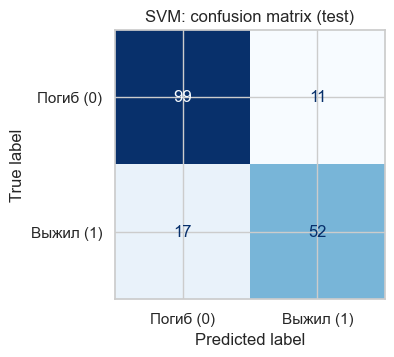

TN=99  FP=11  FN=17  TP=52  ->  ложных 'выжил': 11, пропущенных выживших: 17


In [26]:
svm = tune("SVM", SVC(kernel="rbf", random_state=RANDOM_STATE),
           {"model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03, 0.1]}, scale=True)
evaluate("SVM", svm)

**Выводы по SVM.**
* **Масштабирование действительно необходимо:** без него CV F1 = 0.445, со `StandardScaler` — 0.759 (при тех же гиперпараметрах по умолчанию). Без масштабирования расстояния в RBF-ядре определяются почти только `Fare` (диапазон 0–512) и `Age`, а бинарный `Sex` с разностью 0/1 практически не влияет.
* После подбора (`C=3`, `gamma=0.03`): train F1 = 0.777, test F1 = **0.788** — лучший результат на test; Accuracy 0.844, FP = 11, FN = 17. Переобучения нет (train ≈ test ≈ CV 0.772).
* Небольшой `gamma` даёт гладкую разделяющую поверхность — для 712 объектов с сильными, почти линейными закономерностями (пол, класс) это хорошо работает.
* Встроенной feature importance у SVM с RBF-ядром нет (нет весов признаков) — оцениваем её permutation importance в разделе 7.

### 5.5 K-Nearest Neighbors

KNN не обучает параметров: класс объекта определяется голосованием ближайших (по евклидову расстоянию) объектов train. Расстояние `sqrt(Σ (x_j − x'_j)²)` суммирует вклады признаков **в их исходных единицах**: разница в `Fare` в 50 фунтов «весит» в 50 раз больше, чем разница в поле (0/1). Без масштабирования соседи подбираются фактически только по `Fare` и `Age`. `StandardScaler` приводит признаки к единой шкале (среднее 0, std 1), и все признаки получают сопоставимый вклад.

In [27]:
for scale in [False, True]:
    m = Pipeline([("prep", make_preprocessor(scale)), ("model", KNeighborsClassifier())])
    print(f"KNN, scale={scale}:  CV F1 = {cross_val_score(m, X_train, y_train, cv=CV, scoring='f1').mean():.3f}")

KNN, scale=False:  CV F1 = 0.632


KNN, scale=True:  CV F1 = 0.726


KNN: лучшие параметры {'model__n_neighbors': 15, 'model__weights': 'distance'}, CV F1 = 0.744


,Accuracy,Precision,Recall,F1
train,0.987,0.996,0.971,0.983
test,0.782,0.708,0.739,0.723


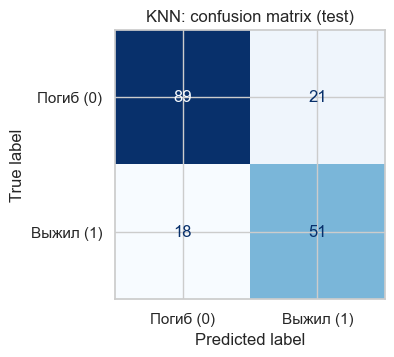

TN=89  FP=21  FN=18  TP=51  ->  ложных 'выжил': 21, пропущенных выживших: 18


In [28]:
knn = tune("KNN", KNeighborsClassifier(),
           {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "model__weights": ["uniform", "distance"]}, scale=True)
evaluate("KNN", knn)

**Выводы по KNN.**
* Масштабирование: CV F1 0.632 без него → 0.726 с ним. Для KNN эффект аналогичен SVM: без масштабирования «соседями» становятся пассажиры с похожей ценой билета, а не с похожим полом и классом.
* Лучшие параметры: `k=15`, `weights="distance"`. Test F1 = 0.723, порог пройден. Precision у KNN самая низкая (0.708, FP = 21) — модель чаще других «спасает» погибших.
* **Train F1 = 0.983 — не признак качества.** При `weights="distance"` каждый объект train является собственным ближайшим соседом с расстоянием 0 (бесконечный вес), поэтому на train KNN почти всегда отвечает правильно. Реальную обобщающую способность показывает только CV (0.744) и test (0.723). Это хороший пример того, почему качество нельзя оценивать на обучающей выборке.

## 6. Честное сравнение моделей (leaderboard)

Условия одинаковы для всех: одно и то же разбиение, одинаковый feature engineering, препроцессинг внутри pipeline, подбор гиперпараметров одной и той же CV на train, одна метрика. Чтобы **выбрать лучшую модель без подглядывания в test**, итоговые конфигурации дополнительно оцениваются повторной кросс-валидацией на train (5 фолдов × 5 повторов).

In [29]:
MODELS = ["Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
cv_scores = {}
for name in MODELS:
    s = cross_val_score(fitted[name], X_train, y_train, cv=rcv, scoring="f1", n_jobs=-1)
    cv_scores[name] = (s.mean(), s.std())

board = pd.DataFrame(results).T
board["Train F1"] = pd.DataFrame(train_results).T["F1"]
board["CV F1 (train)"] = [cv_scores.get(n, (np.nan, np.nan))[0] for n in board.index]
board["CV F1 std"] = [cv_scores.get(n, (np.nan, np.nan))[1] for n in board.index]
board["F1 > 0.70"] = np.where(board["F1"] > F1_THRESHOLD, "да", "нет")
board = board.sort_values("F1", ascending=False)
board.round(3)

,Accuracy,Precision,Recall,F1,Train F1,CV F1 (train),CV F1 std,F1 > 0.70
SVM,0.844,0.825,0.754,0.788,0.777,0.769,0.044,да
Decision Tree,0.832,0.820,0.725,0.769,0.768,0.758,0.050,да
KNN,0.782,0.708,0.739,0.723,0.983,0.739,0.035,да
Random Forest,0.799,0.770,0.681,0.723,0.778,0.771,0.045,да
Gradient Boosting,0.788,0.754,0.667,0.708,0.786,0.766,0.045,да
Dummy (most frequent),0.615,0.000,0.000,0.000,0.000,NaN,NaN,нет


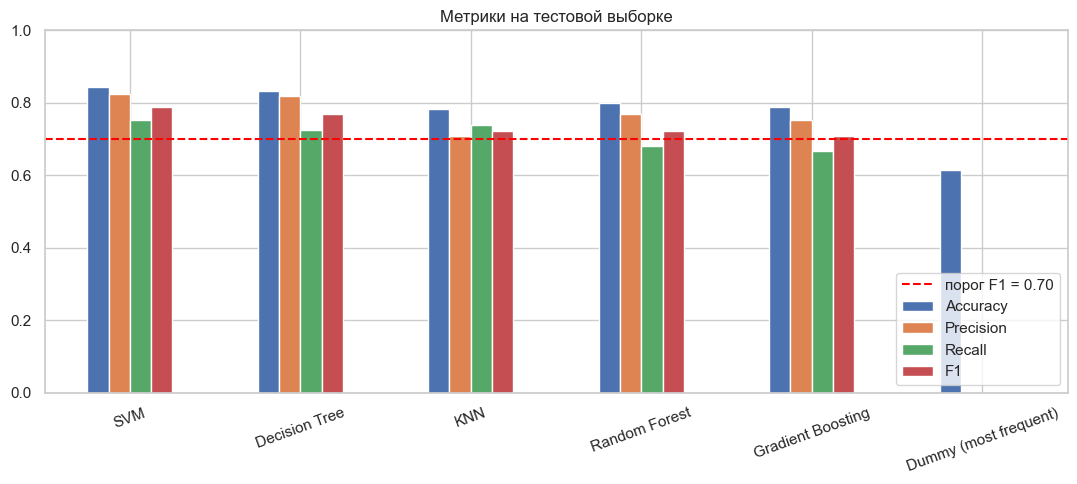

In [30]:
ax = board[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(11, 5), rot=20)
ax.axhline(F1_THRESHOLD, color="red", ls="--", label="порог F1 = 0.70")
ax.set_title("Метрики на тестовой выборке"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

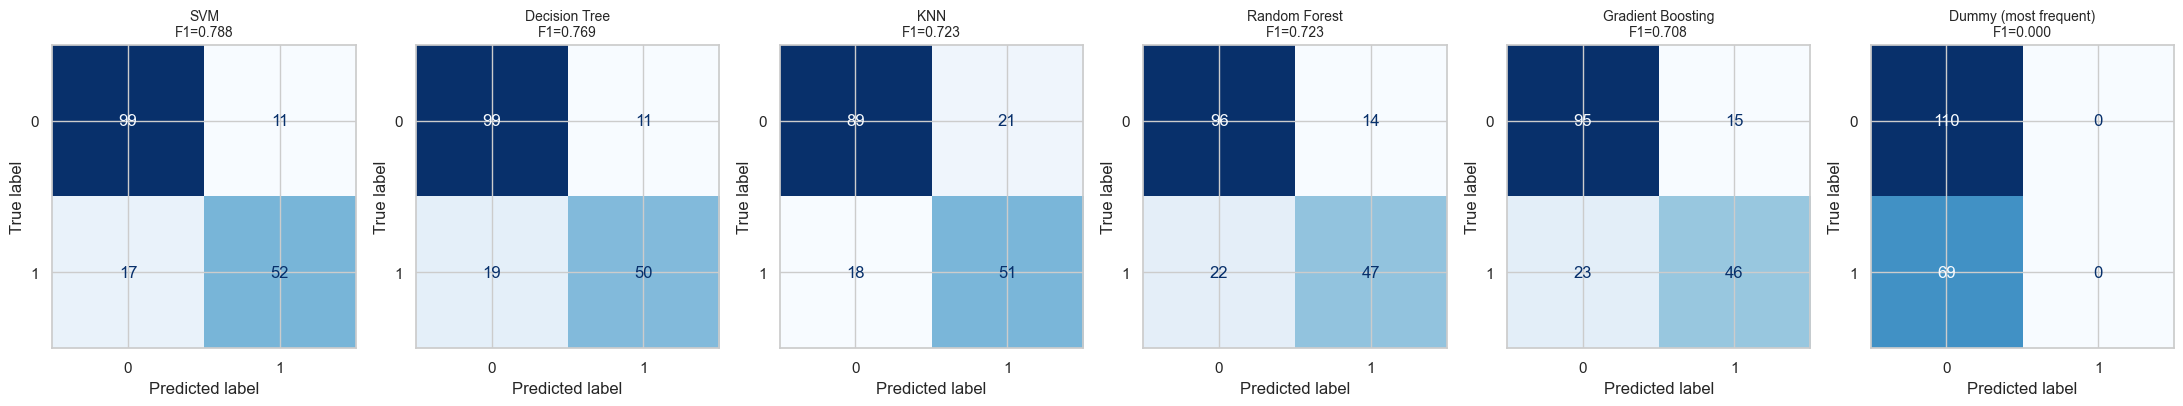

In [31]:
fig, axes = plt.subplots(1, len(board), figsize=(22, 3.8))
for ax, name in zip(axes, board.index):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, ax=ax, cmap="Blues",
                                          colorbar=False, display_labels=["0", "1"])
    ax.set_title(f"{name}\nF1={board.loc[name, 'F1']:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

In [32]:
best_name = max(cv_scores, key=lambda n: cv_scores[n][0])
best = fitted[best_name]
print(f"Лучшая модель по CV F1 на train: {best_name} (CV F1 = {cv_scores[best_name][0]:.3f})")
print(f"Её F1 на test = {results[best_name]['F1']:.3f}")

Лучшая модель по CV F1 на train: Random Forest (CV F1 = 0.771)
Её F1 на test = 0.723


**Выводы по сравнению моделей.**
* **Порог F1 > 0.70 преодолели все пять моделей:** SVM (0.788), Decision Tree (0.769), KNN (0.723), Random Forest (0.723), Gradient Boosting (0.708). Dummy baseline: F1 = 0, Accuracy = 0.615 — каждая модель превосходит его на 17–23 п.п. Accuracy.
* **Выбор лучшей модели — по CV на train, а не по test** (подбор по тесту запрещён). По повторной CV лидирует Random Forest (0.771), но разница между первыми четырьмя моделями (0.758–0.771) намного меньше разброса оценки (std ≈ 0.045). То есть модели **статистически неразличимы**, а их порядок на test (179 объектов, 69 положительных) во многом определяется случайностью разбиения: одна верно/неверно классифицированная выжившая меняет F1 примерно на 0.01. Высокий результат SVM на test — удачное совпадение, а не надёжное превосходство: по CV он на уровне RF.
* **Почему результаты близки.** Задача определяется несколькими сильными признаками (пол/титул, класс, размер семьи), зависимости простые и почти «пороговые» — их одинаково хорошо улавливают и неглубокое дерево, и ансамбли, и SVM. На 712 объектах сложные модели не успевают раскрыть преимущество, а неустранимый шум (кому повезло попасть в шлюпку) ограничивает потолок качества на уровне ~0.77–0.80 F1.
* **Различия по типам ошибок.** У всех моделей, кроме KNN, FN > FP (Recall < Precision): модели консервативно предсказывают «погиб» для мужчин, а среди мужчин есть выжившие, которых признаки не отличают от погибших. KNN единственный со сбалансированными FP/FN (21/18) — локальное голосование соседей меньше опирается на одно глобальное правило «пол».
* **Ансамбли (RF, GB) не выиграли у одиночного дерева** — признаки слишком сильные и немногочисленные, поэтому снижение дисперсии через усреднение почти не даёт выигрыша, а ограниченное по глубине дерево и так не переобучено.

## 7. Feature Importance: сравнение моделей

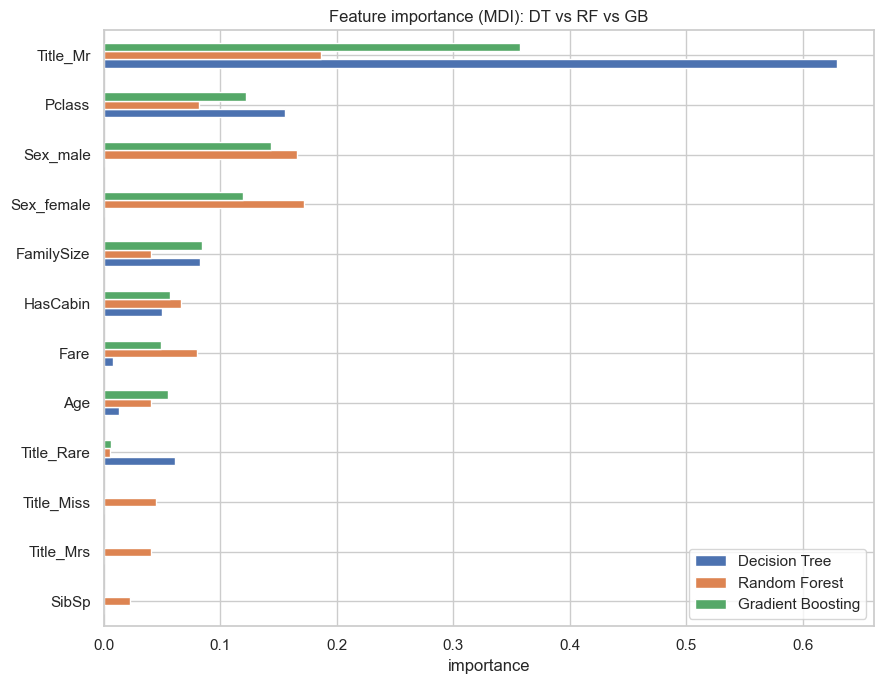

,Decision Tree,Random Forest,Gradient Boosting
Title_Mr,0.630,0.186,0.357
Pclass,0.155,0.082,0.122
Sex_male,0.000,0.166,0.143
Sex_female,0.000,0.172,0.119
FamilySize,0.082,0.041,0.085
HasCabin,0.050,0.066,0.057
Fare,0.008,0.080,0.049
Age,0.013,0.041,0.055
Title_Rare,0.061,0.005,0.006
Title_Miss,0.000,0.045,0.000


In [33]:
imp_all = pd.DataFrame({"Decision Tree": imp_dt, "Random Forest": imp_rf, "Gradient Boosting": imp_gb}).fillna(0)
imp_all = imp_all.loc[imp_all.mean(axis=1).sort_values(ascending=False).index]
imp_all.head(12)[::-1].plot.barh(figsize=(9, 7))
plt.title("Feature importance (MDI): DT vs RF vs GB"); plt.xlabel("importance"); plt.tight_layout(); plt.show()
imp_all.round(3)

MDI-важность (уменьшение impurity) считается по train и завышает признаки с большим числом уникальных значений (`Fare`, `Age`). Кроме того, one-hot «раскалывает» один исходный признак на несколько, а коррелированные признаки (`Sex` ↔ `Title`) делят важность между собой. Поэтому дополнительно считаем **permutation importance** по исходным признакам — насколько падает F1 при перемешивании признака. Её можно посчитать и для SVM/KNN. Считается на test исключительно для интерпретации — ни модели, ни набор признаков по этому результату не меняются.

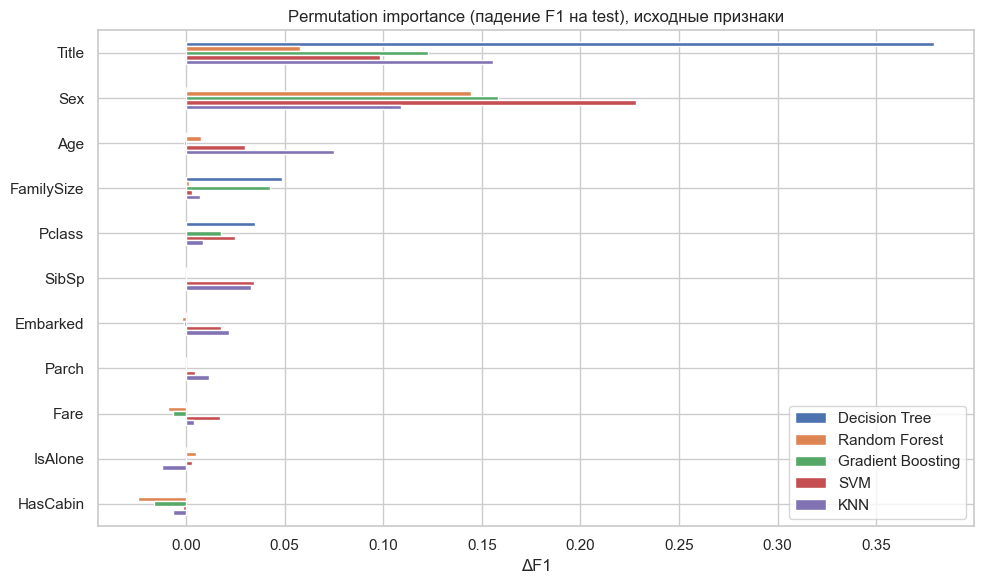

,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Title,0.379,0.058,0.123,0.099,0.156
Sex,0.000,0.144,0.158,0.228,0.109
Age,0.000,0.008,-0.001,0.030,0.075
FamilySize,0.049,0.001,0.043,0.003,0.007
Pclass,0.035,-0.001,0.018,0.025,0.009
SibSp,0.000,0.000,0.000,0.035,0.033
Embarked,0.000,-0.002,-0.001,0.018,0.022
Parch,0.000,0.000,0.000,0.004,0.012
Fare,0.000,-0.009,-0.007,0.017,0.004
IsAlone,0.000,0.005,0.000,0.003,-0.012


In [34]:
perm = {}
for name in MODELS:
    r = permutation_importance(fitted[name], X_test, y_test, scoring="f1", n_repeats=30,
                               random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm)
perm = perm.loc[perm.mean(axis=1).sort_values(ascending=False).index]
ax = perm.plot.barh(figsize=(10, 6)); ax.invert_yaxis()
plt.title("Permutation importance (падение F1 на test), исходные признаки"); plt.xlabel("ΔF1")
plt.tight_layout(); plt.show()
perm.round(3)

**Выводы по важности признаков.**
1. **Наиболее важные признаки во всех моделях — пол/титул.** По MDI на первом месте `Title_Mr` во всех трёх деревьях; по permutation importance первое место делят `Sex` и `Title` (у DT — `Title` 0.38, у RF/GB/SVM — `Sex` 0.14–0.23). Это два представления одного сигнала: `Title` = пол + возрастная группа (`Master` — мальчики) + статус. Модель использует тот из них, который выбрала первым, а второй становится избыточным (у DT permutation importance `Sex` = 0).
2. **Второй уровень — социально-экономический статус и семья:** `Pclass`, `Fare`, `HasCabin`, `FamilySize`, `Age`. У деревьев (DT, GB) — в первую очередь `Pclass` и `FamilySize`, у RF — `Fare`, `HasCabin`, `Pclass` (информация о классе распределена между тремя коррелирующими признаками).
3. **Сравнение DT / RF / GB:** одиночное дерево концентрирует важность в 3–4 признаках (`Title_Mr` 0.63), бустинг — в меньшей степени (0.36), RF распределяет её наиболее равномерно. Состав топ-5 совпадает.
4. **Согласованность с EDA:** важность полностью подтверждает первичный анализ — пол (74% vs 19% выживших) и класс (63% vs 24%) были сильнейшими сигналами, семьи размера 2–4 выживали чаще, наличие каюты связано со статусом. `Embarked`, `Parch`, `SibSp` и индикатор пропуска возраста почти не важны: их связь с выживанием в EDA объяснялась составом пассажиров (например, в Шербуре садилось много пассажиров 1-го класса), и при наличии `Pclass`/`Sex` они не добавляют информации. Отрицательная permutation importance (`HasCabin`, `Fare` у RF) означает, что признак на test фактически не помогает — его вклад в пределах шума.

**Можно ли утверждать, что важный признак — причина выживания?** **Нет.** Feature importance показывает, насколько модель *использует* признак для предсказания, т.е. статистическую связь в данных, а не причинно-следственную:
* важность делится и перераспределяется между коррелированными признаками (`Sex` ↔ `Title`, `Pclass` ↔ `Fare` ↔ `HasCabin`) — «важный» признак может быть просто удобным представителем группы;
* признак может быть лишь прокси настоящей причины: высокий `Fare` сам по себе никого не спасал — он связан с классом, а класс — с расположением кают на верхних палубах ближе к шлюпкам и с приоритетом при посадке;
* `HasCabin` важен не потому, что запись каюты спасает, а потому, что каюты в основном записаны у пассажиров 1-го класса (и, возможно, у выживших, о которых собрали больше информации — признак может содержать пост-фактум информацию);
* для причинных выводов нужен эксперимент или специальные методы causal inference с учётом конфаундеров. Исторически причиной было правило «женщины и дети первыми» и доступ к шлюпкам — модель лишь улавливает его следы в данных.

## 8. Анализ ошибок лучшей модели

In [35]:
analysis = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Embarked", "Cabin"]].copy()
analysis["Title"] = X_test["Title"]
analysis["y_true"] = y_test
analysis["y_pred"] = best.predict(X_test)
analysis["score"] = (best.predict_proba(X_test)[:, 1] if hasattr(best, "predict_proba")
                     else best.decision_function(X_test))
analysis["error"] = np.select([(analysis.y_true == 0) & (analysis.y_pred == 1),
                               (analysis.y_true == 1) & (analysis.y_pred == 0)], ["FP", "FN"], "OK")
analysis["AgeGroup"] = (pd.cut(analysis["Age"], [0, 12, 18, 35, 60, 100],
                               labels=["0-12", "13-18", "19-35", "36-60", "60+"])
                        .cat.add_categories("unknown").fillna("unknown"))
analysis["Segment"] = analysis["Sex"] + ", " + analysis["Pclass"].astype(str) + " класс"
print(best_name)
analysis["error"].value_counts()

Random Forest


error
OK    143
FN     22
FP     14
Name: count, dtype: int64

In [36]:
def group_errors(col):
    g = analysis.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(),
                         "survival_rate": g["y_true"].mean(),
                         "pred_survival_rate": g["y_pred"].mean(),
                         "error_rate": g["error"].apply(lambda e: (e != "OK").mean()),
                         "FP": g["error"].apply(lambda e: (e == "FP").sum()),
                         "FN": g["error"].apply(lambda e: (e == "FN").sum())}).round(2)

for col in ["Sex", "Pclass", "Title", "AgeGroup"]:
    print(f"--- {col} ---")
    display(group_errors(col))

--- Sex ---


,n,survival_rate,pred_survival_rate,error_rate,FP,FN
Sex,,,,,,
female,61,0.74,0.92,0.18,11,0
male,118,0.20,0.04,0.21,3,22


--- Pclass ---


,n,survival_rate,pred_survival_rate,error_rate,FP,FN
Pclass,,,,,,
1,45,0.56,0.42,0.31,4,10
2,34,0.59,0.53,0.12,1,3
3,100,0.24,0.24,0.18,9,9


--- Title ---


,n,survival_rate,pred_survival_rate,error_rate,FP,FN
Title,,,,,,
Master,9,0.67,0.22,0.44,0,4
Miss,41,0.68,0.88,0.20,8,0
Mr,105,0.17,0.00,0.17,0,18
Mrs,19,0.84,1.00,0.16,3,0
Rare,5,0.20,0.80,0.60,3,0


--- AgeGroup ---


,n,survival_rate,pred_survival_rate,error_rate,FP,FN
AgeGroup,,,,,,
0-12,14,0.50,0.36,0.29,1,3
13-18,17,0.47,0.53,0.06,1,0
19-35,74,0.41,0.31,0.20,4,11
36-60,28,0.36,0.36,0.21,3,3
60+,6,0.33,0.33,0.33,1,1
unknown,40,0.30,0.30,0.20,4,4


,n,survival_rate,pred_survival_rate,error_rate,FP,FN
Segment,,,,,,
"male, 1 класс",30,0.37,0.13,0.43,3,10
"female, 3 класс",28,0.50,0.82,0.32,9,0
"male, 2 класс",16,0.19,0.00,0.19,0,3
"male, 3 класс",72,0.14,0.01,0.12,0,9
"female, 1 класс",15,0.93,1.00,0.07,1,0
"female, 2 класс",18,0.94,1.00,0.06,1,0


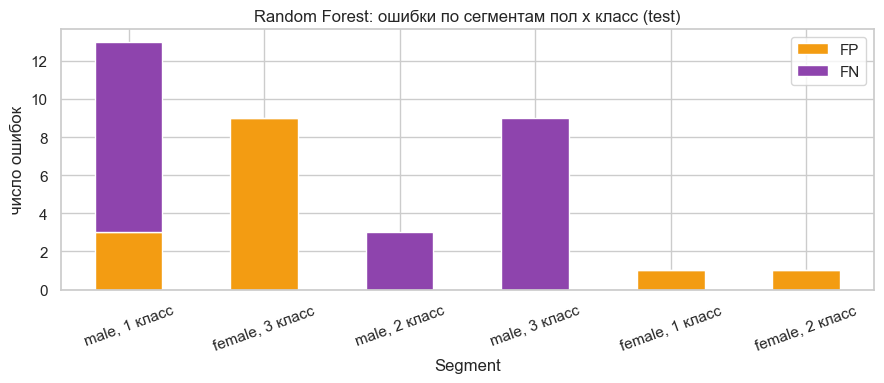

In [37]:
seg = group_errors("Segment").sort_values("error_rate", ascending=False)
display(seg)
seg[["FP", "FN"]].plot.bar(stacked=True, figsize=(9, 4), rot=20, color=["#f39c12", "#8e44ad"],
                          title=f"{best_name}: ошибки по сегментам пол x класс (test)")
plt.ylabel("число ошибок"); plt.tight_layout(); plt.show()

### Примеры ошибочно классифицированных пассажиров

In [38]:
cols = ["Name", "Sex", "Age", "Pclass", "Fare", "SibSp", "Parch", "Embarked", "Cabin", "y_true", "y_pred", "score", "error"]
print("False Negatives (выжили, но модель сказала 'погиб'), самые уверенные ошибки:")
display(analysis[analysis.error == "FN"][cols].sort_values("score").head(8))
print("False Positives (погибли, но модель сказала 'выжил'), самые уверенные ошибки:")
display(analysis[analysis.error == "FP"][cols].sort_values("score", ascending=False).head(8))

False Negatives (выжили, но модель сказала 'погиб'), самые уверенные ошибки:


,Name,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,Cabin,y_true,y_pred,score,error
271,"Tornquist, Mr. William Henry",male,25.0,3,0.0000,0,0,S,NaN,1,0,0.106455,FN
804,"Hedman, Mr. Oskar Arvid",male,27.0,3,6.9750,0,0,S,NaN,1,0,0.106996,FN
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,8.1125,0,0,S,NaN,1,0,0.110730,FN
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.0000,0,0,S,NaN,1,0,0.111492,FN
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,7.7958,0,0,S,NaN,1,0,0.112484,FN
570,"Harris, Mr. George",male,62.0,2,10.5000,0,0,S,NaN,1,0,0.112724,FN
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,0,0,C,NaN,1,0,0.128426,FN
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958,0,0,C,NaN,1,0,0.128726,FN


False Positives (погибли, но модель сказала 'выжил'), самые уверенные ошибки:


,Name,Sex,Age,Pclass,Fare,SibSp,Parch,Embarked,Cabin,y_true,y_pred,score,error
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,1,2,S,C22 C26,0,1,0.887304,FP
199,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,2,13.0000,0,0,S,NaN,0,1,0.759886,FP
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,7.6292,0,0,Q,NaN,0,1,0.694519,FP
501,"Canavan, Miss. Mary",female,21.0,3,7.7500,0,0,Q,NaN,0,1,0.684733,FP
593,"Bourke, Miss. Mary",female,NaN,3,7.7500,0,2,Q,NaN,0,1,0.662801,FP
245,"Minahan, Dr. William Edward",male,44.0,1,90.0000,2,0,Q,C78,0,1,0.640229,FP
578,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,3,14.4583,1,0,C,NaN,0,1,0.636051,FP
799,"Van Impe, Mrs. Jean Baptiste (Rosalie Paula Go...",female,30.0,3,24.1500,1,1,S,NaN,0,1,0.589708,FP


**Анализ ошибок лучшей по CV модели (Random Forest).**
* **Чаще встречаются FN:** 22 FN против 14 FP (из 179 объектов, всего 36 ошибок, Accuracy 0.80). Модель склонна недооценивать шансы выживания.
* **Модель по сути выучила правило «женщина → выжила, мужчина → погиб»:** среди женщин она предсказывает выживание 92% (реально 74%), среди мужчин — 4% (реально 20%). Отсюда структура ошибок: **все 22 FN — мужчины, 11 из 14 FP — женщины.**
* **Группы с наибольшей ошибкой** — те, где правило «по полу» не работает:
  * **мужчины 1-го класса** — error rate 43% (10 FN, 3 FP): выжили 37% из них, это наиболее «неопределённая» группа, и признаки не позволяют отличить выживших от погибших;
  * **женщины 3-го класса** — 32% ошибок, все 9 — FP: реальная выживаемость 50%, а модель предсказывает выживание 82% этой группы;
  * **мальчики (`Master`)** — 44% ошибок (4 FN из 9): модель недооценивает их шансы, т.к. их мало в train (~30 объектов);
  * титул **`Rare`** — 3 FP из 5 (врачи/военные/духовенство мужского пола в 1-м классе — модель путается из-за редкости группы).
* **Примеры ошибок и возможные причины:**
  * *FN — Tornquist, Mr. William Henry* (мужчина, 25 лет, 3-й класс, `Fare = 0`, один) и подобные ему *Hedman, Jalsevac, Leeni*: молодые одинокие мужчины 3-го класса — группа с выживаемостью ~14%. По имеющимся признакам их выживание не предсказуемо: вероятно, решили факторы, которых нет в данных (место в момент катастрофы, случайное попадание в шлюпку). Модель даёт им ~0.11 — это «разумная» ошибка.
  * *FP — Allison, Miss. Helen Loraine* (девочка 2 лет, 1-й класс, каюта C22) — по всем признакам должна была выжить (score 0.89), но её семья, по историческим данным, задержалась на борту, разыскивая младшего ребёнка. Это пример объективно непредсказуемого исхода.
  * *FP — O'Sullivan, Canavan, Bourke (Miss, 3-й класс, Queenstown)* — женщины 3-го класса, где выживаемость лишь 50%; модель переоценивает влияние пола для этого класса.
  * *FP — Minahan, Dr. William Edward* (мужчина 1-го класса, титул `Rare`) — редкий титул смешал его с группой с высокой выживаемостью, хотя взрослые мужчины 1-го класса чаще погибали.
* **Вывод:** ошибки сосредоточены в «пограничных» группах с выживаемостью около 30–60%, где доступные признаки не разделяют исходы. Улучшить качество можно разве что признаками, которых в данных нет (палуба/расположение каюты, групповые связи между попутчиками), а не усложнением модели.

### Проверка: не опирается ли качество на идентифицирующие признаки

1. Программно проверяем, что среди признаков модели нет `PassengerId`, `Name`, `Ticket`, `Cabin`.
2. Демонстрация, почему их нельзя использовать: дерево на одном `PassengerId` и на одном `Ticket` «запоминает» train, но на test не обобщается.
3. Устойчивость: лучшая модель без `Title` (единственного признака, производного от `Name`) — если качество не рушится, модель не «узнаёт» конкретных людей по имени, а `Title` лишь дублирует пол/возраст.

In [39]:
used = set(best.named_steps["prep"].get_feature_names_out())
print("Признаки модели:", sorted(used))
assert not used & {"PassengerId", "Name", "Ticket", "Cabin"}, "в модели есть идентификаторы!"
print("Идентифицирующих признаков в модели нет.")

Признаки модели: ['Age', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'HasCabin', 'IsAlone', 'Parch', 'Pclass', 'Sex_female', 'Sex_male', 'SibSp', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'missingindicator_Age']
Идентифицирующих признаков в модели нет.


In [40]:
id_rows = []
for col in ["PassengerId", "Ticket"]:
    model = Pipeline([("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                      ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE))])
    Xi_tr, Xi_te = df.loc[X_train.index, [col]].astype(str), df.loc[X_test.index, [col]].astype(str)
    if col == "PassengerId":  # число -> оставляем числом
        Xi_tr, Xi_te = df.loc[X_train.index, [col]], df.loc[X_test.index, [col]]
    model.fit(Xi_tr, y_train)
    id_rows.append({"признак": col,
                    "train Acc": accuracy_score(y_train, model.predict(Xi_tr)),
                    "train F1": f1_score(y_train, model.predict(Xi_tr)),
                    "test Acc": accuracy_score(y_test, model.predict(Xi_te)),
                    "test F1": f1_score(y_test, model.predict(Xi_te))})
pd.DataFrame(id_rows).set_index("признак").round(3)

,train Acc,train F1,test Acc,test F1
признак,,,,
PassengerId,1.000,1.000,0.615,0.000
Ticket,0.963,0.952,0.408,0.509


In [41]:
cat_no_title = [c for c in CAT_FEATURES if c != "Title"]
scaled = "scale" in best.named_steps["prep"].named_transformers_["num"].named_steps
best_nt = Pipeline([("prep", make_preprocessor(scaled, cat_no_title)), ("model", clone(best.named_steps["model"]))])
X_train_nt, X_test_nt = X_train.drop(columns="Title"), X_test.drop(columns="Title")
cv_nt = cross_val_score(best_nt, X_train_nt, y_train, cv=rcv, scoring="f1").mean()
best_nt.fit(X_train_nt, y_train)
pd.DataFrame({"CV F1 (train)": [cv_scores[best_name][0], cv_nt],
              "test F1": [results[best_name]["F1"], f1_score(y_test, best_nt.predict(X_test_nt))]},
             index=[f"{best_name} (с Title)", f"{best_name} (без Title)"]).round(3)

,CV F1 (train),test F1
Random Forest (с Title),0.771,0.723
Random Forest (без Title),0.747,0.734


**Выводы по проверке на утечку и запоминание.**
* В модели нет ни одного идентифицирующего признака (`PassengerId`, `Name`, `Ticket`, `Cabin`) — проверено программно.
* **Демонстрация вреда идентификаторов:** дерево на одном `PassengerId` даёт на train Accuracy = F1 = 1.0 (идеально запоминает номер → исход), а на test F1 = 0 и Accuracy = 0.615 — ровно уровень Dummy. Дерево на `Ticket` — train Accuracy 0.96, test Accuracy 0.41, **хуже baseline**. Это классическое «бессмысленное запоминание»: идеальное качество на train при отсутствии обобщения. Если бы такие признаки попали в модель, они дали бы ложно высокую оценку на train/CV и ухудшение на новых данных.
* **Титул не является «идентификатором»:** без `Title` RF теряет ~0.02 F1 на CV (0.771 → 0.747), а на test даже чуть лучше (0.734 vs 0.723) — т.е. качество держится на поле, классе и семье, а `Title` лишь уточняет возрастную группу (мальчики `Master`). У `Title` всего 5 значений, каждое — у десятков пассажиров, поэтому запомнить конкретного человека по нему невозможно.
* Признаков с «нежелательной» информацией из будущего (например, номер шлюпки или тела, как в расширенных версиях датасета) в этом датасете нет. Единственный потенциально спорный признак — `HasCabin` (каюты могли быть дозаписаны преимущественно у выживших), но его вклад мал (permutation importance ≈ 0 или отрицательна), так что высокое качество с ним не связано.
* Итог: качество моделей ~0.71–0.79 F1 объясняется осмысленными признаками и согласуется с результатами EDA; необъяснимо высокого качества нет.

## 9. Итоговые выводы

| Модель | Accuracy | Precision | Recall | F1 (test) | CV F1 (train) | F1 > 0.70 |
|---|---|---|---|---|---|---|
| SVM (RBF, C=3, γ=0.03) | 0.844 | 0.825 | 0.754 | **0.788** | 0.769 | да |
| Decision Tree (depth=3) | 0.832 | 0.820 | 0.725 | 0.769 | 0.758 | да |
| KNN (k=15, distance) | 0.782 | 0.708 | 0.739 | 0.723 | 0.739 | да |
| Random Forest (depth=4) | 0.799 | 0.770 | 0.681 | 0.723 | **0.771** | да |
| Gradient Boosting (depth=2) | 0.788 | 0.754 | 0.667 | 0.708 | 0.766 | да |
| Dummy (most frequent) | 0.615 | 0.000 | 0.000 | 0.000 | — | нет |

1. **Данные.** 891 пассажир, 38% выживших. Главные факторы — пол, класс, возраст (дети), размер семьи. `PassengerId`, `Name`, `Ticket`, `Cabin` — идентификаторы/почти уникальные значения, исключены; из `Name` взят только обобщающийся титул, из `Cabin` — флаг наличия.
2. **Корректность эксперимента.** Один стратифицированный split (80/20, `random_state=42`) для всех моделей; все преобразования с параметрами (импутация, OHE, масштабирование) — внутри `Pipeline` и обучаются только на train; гиперпараметры и лучшая модель выбраны по кросс-валидации на train; test использован только для финальной оценки и интерпретации.
3. **Качество.** Все пять моделей прошли порог F1 > 0.70 и намного превзошли baseline (F1 = 0). Лучший результат на test — SVM (F1 = 0.788); лучшая по честному CV-критерию — Random Forest (CV F1 = 0.771, test 0.723). Разница между моделями (кроме KNN) меньше разброса CV, т.е. алгоритмы на этой задаче практически равноценны.
4. **Переобучение** обнаружено у неограниченного дерева (train F1 0.98 vs test 0.73) и устранено ограничением глубины. Масштабирование критично для SVM (CV F1 0.45 → 0.76) и KNN (0.63 → 0.73) и не нужно для деревьев.
5. **Feature importance** у DT, RF, GB согласуется с EDA: пол/титул ≫ класс/стоимость билета/каюта > размер семьи, возраст. Важность ≠ причинность.
6. **Ошибки** — в основном FN (выжившие мужчины, особенно 1-го класса) и FP среди женщин 3-го класса: модель опирается на правило «женщины выживают», а в этих группах оно выполняется хуже всего.